# 06 · YOLO11 sobre recortes de 1024 px

**Problema del modelo original** (`04_YOLO11_baseline_detection`): la foto completa (5120×5120) se reducía a 640 px, es decir, **8 veces más chica**. Un hilo de 40 px quedaba en 5 px y desaparecía. Resultado: mAP50 = 0.25, con recall casi nulo en hilos, manchas y rafia.

**Solución:** entrenar con recortes de 1024 px a resolución nativa y, en inferencia, recortar la foto de la toalla de la misma manera y unir las detecciones con NMS. Esto es compatible con producción: la máquina toma una foto por toalla, esa foto se divide en ~15 recortes y el resultado se combina en una decisión por toalla.

Entrenamiento (≈3 h en una RTX 3060 Laptop):
```bash
python scripts/05_train_yolo_tiles.py --model yolo11s.pt --epochs 80
```

In [1]:
import sys, time, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from galia import config as C, viz
from galia.data import load_manifest, load_image, load_boxes
from galia.models import YoloTilePredictor
viz.setup()
RUN = C.RUNS_DIR / "yolo11s_tiles"
WEIGHTS = C.MODELS_DIR / "yolo11s_tiles.pt"

## 1. Curvas de entrenamiento

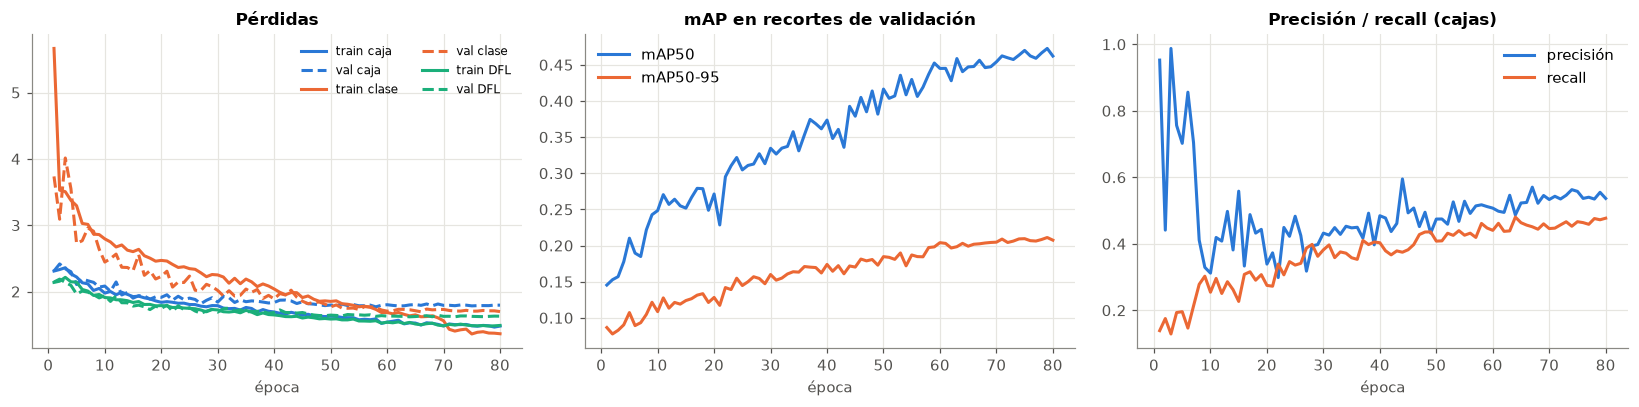

In [2]:
res = pd.read_csv(RUN / "results.csv"); res.columns = res.columns.str.strip()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for i, (k, lab) in enumerate([("box_loss", "caja"), ("cls_loss", "clase"), ("dfl_loss", "DFL")]):
    axes[0].plot(res.epoch, res[f"train/{k}"], color=viz.PALETTE[i], label=f"train {lab}")
    axes[0].plot(res.epoch, res[f"val/{k}"], color=viz.PALETTE[i], ls="--", label=f"val {lab}")
axes[0].set_title("Pérdidas"); axes[0].set_xlabel("época"); axes[0].legend(fontsize=8, ncol=2)
axes[1].plot(res.epoch, res["metrics/mAP50(B)"], label="mAP50")
axes[1].plot(res.epoch, res["metrics/mAP50-95(B)"], label="mAP50-95")
axes[1].set_title("mAP en recortes de validación"); axes[1].set_xlabel("época"); axes[1].legend()
axes[2].plot(res.epoch, res["metrics/precision(B)"], label="precisión")
axes[2].plot(res.epoch, res["metrics/recall(B)"], label="recall")
axes[2].set_title("Precisión / recall (cajas)"); axes[2].set_xlabel("época"); axes[2].legend()
plt.tight_layout()

## 2. Métricas por clase (recortes de validación)
`Etiqueta` es el **control**: es un objeto fácil, siempre presente. Si el modelo lo detecta bien, el pipeline de datos y la escala son correctos.

In [3]:
from ultralytics import YOLO
m = YOLO(str(WEIGHTS))
val = m.val(data=str(C.YOLO_TILES_DIR / "data.yaml"), imgsz=C.YOLO_TILE, batch=8, verbose=False, plots=False, workers=2)
names = [m.names[i] for i in range(len(m.names))]
per_class = pd.DataFrame({
    "clase": names,
    "precisión": val.box.p, "recall": val.box.r,
    "mAP50": val.box.ap50, "mAP50-95": val.box.ap,
}).set_index("clase")
per_class.loc["todas (media)"] = [val.box.mp, val.box.mr, val.box.map50, val.box.map]
per_class.round(3)

Ultralytics 8.4.215  Python-3.11.18 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)


YOLO11s summary (fused): 100 layers, 9,415,509 parameters, 0 gradients, 21.4 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 531.8±48.1 MB/s, size: 372.6 KB)


val: Scanning C:\Users\Marcony1\OneDrive - Fundacion Universidad de las Americas Puebla\Documents\Git\textile-image-defect-detector\data\yolo_tiles\val\labels.cache... 723 images, 277 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 723/723  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 1% ──────────── 1/91 14.2s/it 4.3s<21:17

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 2% ──────────── 2/91 1.9it/s 4.4s<46.7s

... (88 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 91/91 4.7it/s 19.4s

                   all        723        601      0.563      0.474      0.475      0.212


Speed: 1.7ms preprocess, 17.8ms inference, 0.0ms loss, 0.8ms postprocess per image


,precisión,recall,mAP50,mAP50-95
clase,,,,
Etiqueta,0.912,0.957,0.956,0.633
Mancha,0.473,0.221,0.264,0.096
Hilo,0.490,0.319,0.228,0.073
Costura,0.390,0.275,0.247,0.067
Tejido,0.316,0.273,0.264,0.108
Tenido,0.749,0.518,0.554,0.202
Empalme,0.611,0.757,0.813,0.306
todas (media),0.563,0.474,0.475,0.212


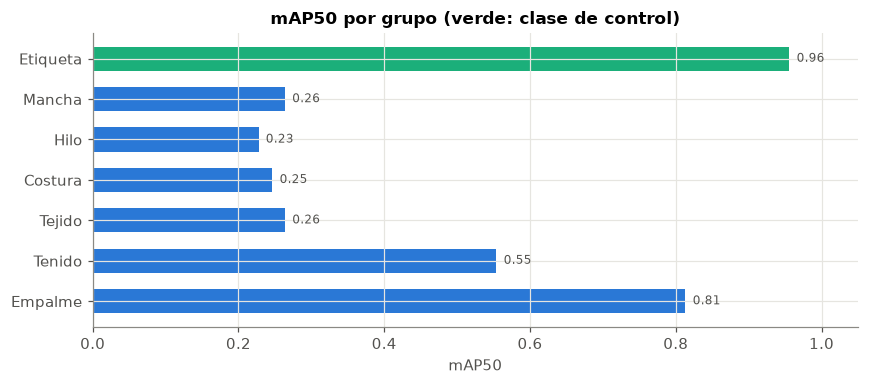

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
pc = per_class.drop("todas (media)")
cols = [viz.PALETTE[2] if c == "Etiqueta" else viz.PALETTE[0] for c in pc.index]
ax.barh(pc.index, pc["mAP50"], color=cols, height=0.6)
for y, v in enumerate(pc["mAP50"]):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8, color="#52514e")
ax.invert_yaxis(); ax.set_xlim(0, 1.05); ax.set_xlabel("mAP50")
ax.set_title("mAP50 por grupo (verde: clase de control)")
plt.tight_layout()

> **Nota:** el mAP mide si cada caja se ubica bien. Para la empresa, lo que importa es **si la toalla con defecto se detecta**, aunque la caja no coincida exactamente con la anotación. Esa métrica a nivel toalla está en el notebook 09.
> El mAP del modelo original (0.25) se calculó con otras clases y otro set de validación, así que no es directamente comparable.

## 3. Inferencia sobre la foto completa de una toalla (como en producción)

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


Tiempo por toalla: 0.29 s (GPU, incluye recorte y NMS)


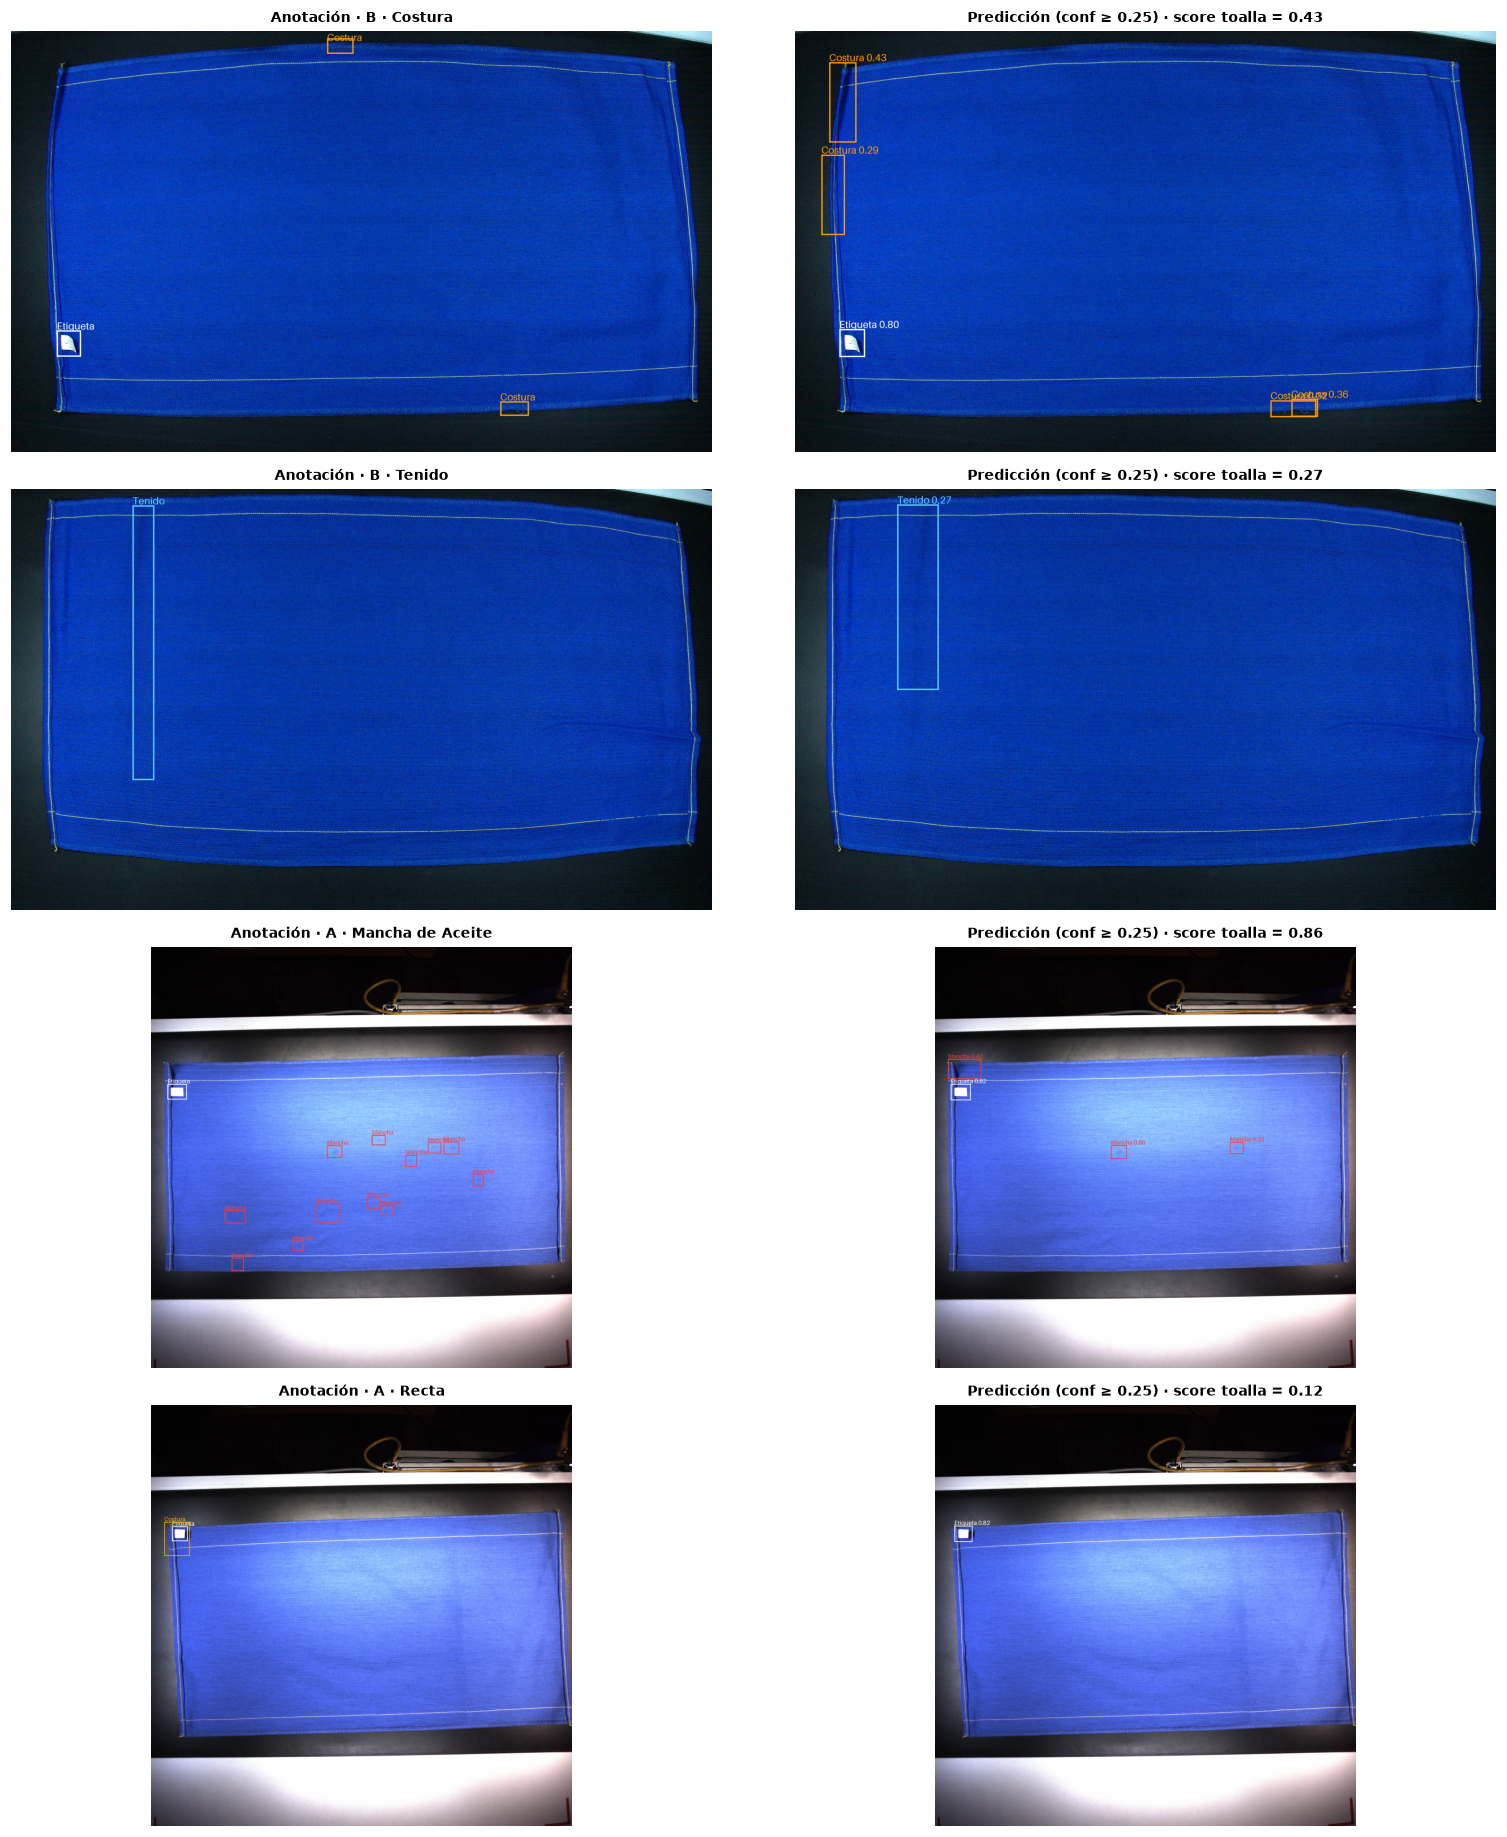

In [5]:
pred = YoloTilePredictor(WEIGHTS)
df = load_manifest()
test = df[df.split == "test"]
ex = pd.concat([test[(test.source == "B") & (test.n_defect_boxes > 0)].sample(2, random_state=3),
                test[(test.source == "A") & (test.n_defect_boxes > 0)].sample(2, random_state=3)])
times = []
fig, axes = plt.subplots(len(ex), 2, figsize=(15, 4.2 * len(ex)))
for (ax_gt, ax_pr), r in zip(axes, ex.itertuples()):
    img, s = load_image(r.path, r.source)
    gt = load_boxes(r.label_path, r.width, r.height); gt[:, 1:] *= s
    t0 = time.time(); out = pred(img); times.append(time.time() - t0)
    ax_gt.imshow(viz.draw_boxes(img, gt)); ax_gt.set_title(f"Anotación · {r.source} · {r.category}", fontsize=9)
    ax_pr.imshow(viz.draw_boxes(img, out.detections, min_conf=0.25))
    ax_pr.set_title(f"Predicción (conf ≥ 0.25) · score toalla = {out.score:.2f}", fontsize=9)
    ax_gt.set_axis_off(); ax_pr.set_axis_off()
plt.tight_layout()
print(f"Tiempo por toalla: {np.mean(times[1:] or times):.2f} s (GPU, incluye recorte y NMS)")

### Acercamiento a las detecciones

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


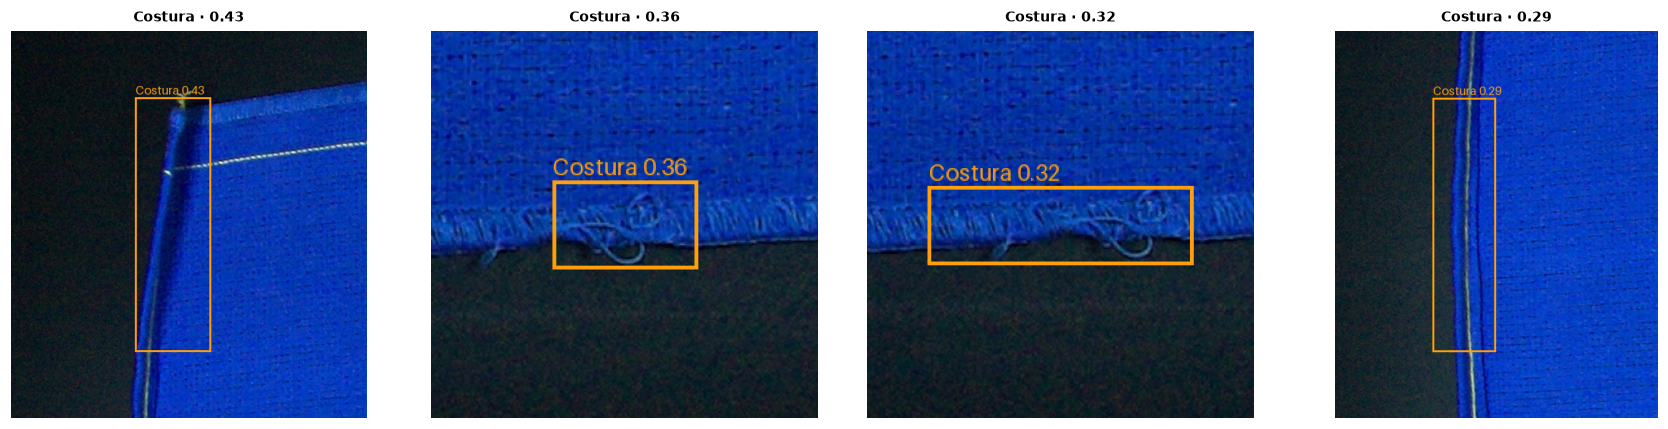

In [6]:
r = ex.iloc[0]
img, s = load_image(r.path, r.source)
out = pred(img)
d = out.detections[(out.detections[:, 4] >= 0.25) & np.isin(out.detections[:, 5], C.DEFECT_CLASS_IDS)]
d = d[np.argsort(-d[:, 4])][:4]
if len(d):
    fig, axes = plt.subplots(1, len(d), figsize=(4 * len(d), 4), squeeze=False)
    for ax, b in zip(axes[0], d):
        cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
        half = max(150, (b[2] - b[0]) * 0.8, (b[3] - b[1]) * 0.8)
        x1, y1 = int(max(0, cx - half)), int(max(0, cy - half))
        x2, y2 = int(min(img.shape[1], cx + half)), int(min(img.shape[0], cy + half))
        bb = b.copy(); bb[[0, 2]] -= x1; bb[[1, 3]] -= y1
        ax.imshow(viz.draw_boxes(img[y1:y2, x1:x2], [bb], width=3)); ax.set_axis_off()
        ax.set_title(f"{C.CLASSES[int(b[5])]} · {b[4]:.2f}", fontsize=9)
    plt.tight_layout()